In [2]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter
import pandas as pd

np.set_printoptions(precision=4,suppress=True)

DATA_DIR="TEAM_11"

if not os.path.isdir(DATA_DIR):
    if not os.path.isfile(ZIP_PATH):
        raise FileNotFoundError("Place TEAM_11(3).zip in the same folder as this notebook.")
    with zipfile.ZipFile(ZIP_PATH,"r") as z:
        z.extractall(".")

print("Dataset folder:",os.path.abspath(DATA_DIR))

Dataset folder: c:\Users\welcome\Pictures\prml\assignment 8\number 135\TEAM_11


In [3]:
#random number
from math import log,sqrt,cos,sin,pi

seed=42

def random_number():
    global seed
    seed=(1664525*seed+1013904223)%(2**32)
    return seed/(2**32)

def box_muller():
    u1=random_number()
    u2=random_number()
    while u1==0:
        u1=random_number()
    z1=sqrt(-2*log(u1))*cos(2*pi*u2)
    z2=sqrt(-2*log(u1))*sin(2*pi*u2)
    return np.array([z1,z2])

def gaussian_noise(shape):
    count=int(np.prod(shape))
    values=[]
    while len(values)<count:
        values.extend(box_muller().tolist())
    return np.array(values[:count]).reshape(shape)

In [4]:
def load_split(split):
    X=[]
    y=[]
    split_path=os.path.join(DATA_DIR,split)
    for label in sorted(os.listdir(split_path)):
        class_path=os.path.join(split_path,label)
        if not os.path.isdir(class_path):
            continue
        for filename in sorted(os.listdir(class_path)):
            if filename.lower().endswith((".png",".jpg",".jpeg")):
                image=Image.open(os.path.join(class_path,filename)).convert("L").resize((28,28))
                X.append(np.asarray(image,dtype=np.float32).reshape(-1))
                y.append(int(label))
    return np.asarray(X,dtype=np.float32),np.asarray(y,dtype=int)

X_train,y_train=load_split("train")
X_dev,y_dev=load_split("dev")
X_test,y_test=load_split("test")

print("Train:",X_train.shape,Counter(y_train))
print("Dev:",X_dev.shape,Counter(y_dev))
print("Test:",X_test.shape,Counter(y_test))

Train: (14637, 784) Counter({np.int64(1): 5383, np.int64(3): 4886, np.int64(5): 4368})
Dev: (3657, 784) Counter({np.int64(1): 1359, np.int64(3): 1245, np.int64(5): 1053})
Test: (3037, 784) Counter({np.int64(1): 1135, np.int64(3): 1010, np.int64(5): 892})


In [5]:
def accuracy_score(y_true,y_pred):
    return np.mean(y_true==y_pred)*100

def confusion_matrix_custom(y_true,y_pred,classes):
    matrix=np.zeros((len(classes),len(classes)),dtype=int)
    lookup={label:i for i,label in enumerate(classes)}
    for actual,predicted in zip(y_true,y_pred):
        matrix[lookup[actual],lookup[predicted]]+=1
    return matrix

CLASSES=np.array(sorted(np.unique(y_train)))

def show_confusion_matrix(y_true,y_pred,title):
    matrix=confusion_matrix_custom(y_true,y_pred,CLASSES)
    plt.figure(figsize=(5,4))
    plt.imshow(matrix,cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.xticks(range(len(CLASSES)),CLASSES)
    plt.yticks(range(len(CLASSES)),CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            plt.text(j,i,str(matrix[i,j]),ha="center",va="center")
    plt.colorbar()
    plt.tight_layout()
    plt.show()
    return matrix

In [6]:

class GMM:
    def __init__(self,n_components=3,max_iter=20,reg=1e-5):
        self.n_components=n_components
        self.max_iter=max_iter
        self.reg=reg

    def log_gaussian(self,X,means,variances):
        diff=X[:,None,:]-means[None,:,:]
        return -0.5*np.sum(np.log(2*pi*variances)[None,:,:]+(diff**2)/variances[None,:,:],axis=2)

    def logsumexp(self,A):
        maximum=np.max(A,axis=1,keepdims=True)
        return maximum[:,0]+np.log(np.sum(np.exp(A-maximum),axis=1)+1e-12)

    def kkt_weights(self,nk):
        nk=np.maximum(nk,1e-12)
        weights=nk/np.sum(nk)
        return weights

    def fit(self,X):
        n,d=X.shape
        k=self.n_components

        indices=np.linspace(0,n-1,k,dtype=int)
        self.means=X[indices].copy()+gaussian_noise((k,d))*0.001

        global_var=np.var(X,axis=0)+self.reg
        self.variances=np.tile(global_var,(k,1))
        self.weights=np.ones(k)/k

        for _ in range(self.max_iter):
            log_prob=self.log_gaussian(X,self.means,self.variances)+np.log(self.weights+1e-12)

            maximum=np.max(log_prob,axis=1,keepdims=True)
            responsibilities=np.exp(log_prob-maximum)
            responsibilities/=np.sum(responsibilities,axis=1,keepdims=True)+1e-12

            nk=np.sum(responsibilities,axis=0)+1e-8

            self.weights=self.kkt_weights(nk)
            self.means=(responsibilities.T@X)/nk[:,None]

            diff=X[:,None,:]-self.means[None,:,:]
            self.variances=np.sum(responsibilities[:,:,None]*diff**2,axis=0)/nk[:,None]
            self.variances+=self.reg

        return self

    def score_samples(self,X):
        values=self.log_gaussian(X,self.means,self.variances)+np.log(self.weights+1e-12)
        return self.logsumexp(values)


class GMMClassifier:
    def __init__(self,n_components=3,max_iter=20):
        self.n_components=n_components
        self.max_iter=max_iter
        self.models={}

    def fit(self,X,y):
        self.classes=np.unique(y)

        for label in self.classes:
            model=GMM(self.n_components,self.max_iter)
            model.fit(X[y==label])
            self.models[label]=model

        return self

    def predict(self,X):
        scores=np.column_stack([
            self.models[label].score_samples(X)
            for label in self.classes
        ])
        return self.classes[np.argmax(scores,axis=1)]


In [7]:
class LDA:
    def __init__(self,reg=1e-4):
        self.reg=reg

    def fit(self,X,y):
        self.classes=np.unique(y)
        overall=np.mean(X,axis=0)
        d=X.shape[1]
        sw=np.zeros((d,d))
        sb=np.zeros((d,d))
        for label in self.classes:
            group=X[y==label]
            mean=np.mean(group,axis=0)
            centered=group-mean
            sw+=centered.T@centered
            diff=(mean-overall).reshape(-1,1)
            sb+=len(group)*(diff@diff.T)
        sw+=self.reg*np.eye(d)
        values,vectors=np.linalg.eigh(np.linalg.pinv(sw)@sb)
        order=np.argsort(values)[::-1]
        self.components=vectors[:,order[:len(self.classes)-1]]
        self.means={}
        for label in self.classes:
            self.means[label]=np.mean(X[y==label]@self.components,axis=0)
        return self

    def predict(self,X):
        projected=X@self.components
        distances=np.column_stack([np.sum((projected-self.means[label])**2,axis=1) for label in self.classes])
        return self.classes[np.argmin(distances,axis=1)]

In [8]:
class KNN:
    def __init__(self,k=3,batch_size=100):
        self.k=k
        self.batch_size=batch_size

    def fit(self,X,y):
        self.X=X
        self.y=y
        self.classes=np.unique(y)
        return self

    def predict(self,X):
        predictions=[]
        train_norm=np.sum(self.X**2,axis=1)
        for start in range(0,len(X),self.batch_size):
            batch=X[start:start+self.batch_size]
            distances=np.sum(batch**2,axis=1)[:,None]+train_norm[None,:]-2*batch@self.X.T
            nearest=np.argpartition(distances,self.k-1,axis=1)[:,:self.k]
            for row in nearest:
                labels=self.y[row]
                counts=np.array([np.sum(labels==label) for label in self.classes])
                predictions.append(self.classes[np.argmax(counts)])
        return np.asarray(predictions)

In [9]:
class LinearSVM:
    def __init__(self,learning_rate=0.01,regularization=0.001,epochs=20):
        self.learning_rate=learning_rate
        self.regularization=regularization
        self.epochs=epochs

    def fit(self,X,y):
        self.classes=np.unique(y)
        n,d=X.shape
        self.weights=np.zeros((len(self.classes),d))
        self.bias=np.zeros(len(self.classes))
        for index,label in enumerate(self.classes):
            targets=np.where(y==label,1.0,-1.0)
            w=np.zeros(d)
            b=0.0
            for epoch in range(self.epochs):
                scores=X@w+b
                margins=targets*scores
                active=margins<1
                grad_w=self.regularization*w-(X[active].T@targets[active])/n
                grad_b=-np.sum(targets[active])/n
                rate=self.learning_rate/(1+0.05*epoch)
                w-=rate*grad_w
                b-=rate*grad_b
            self.weights[index]=w
            self.bias[index]=b
        return self

    def predict(self,X):
        scores=X@self.weights.T+self.bias
        return self.classes[np.argmax(scores,axis=1)]

In [10]:
def run_models(Xtr,ytr,Xval,yval,Xte,yte):
    models={
        "GMM":GMMClassifier(n_components=3,max_iter=20),
        "LDA":LDA(),
        "K-NN":KNN(k=3),
        "SVM":LinearSVM(learning_rate=0.01,regularization=0.001,epochs=20)
    }
    results={}
    fitted={}
    for name,model in models.items():
        print("Training",name)
        model.fit(Xtr,ytr)
        val_pred=model.predict(Xval)
        test_pred=model.predict(Xte)
        results[name]={
            "Dev Accuracy":accuracy_score(yval,val_pred),
            "Test Accuracy":accuracy_score(yte,test_pred)
        }
        fitted[name]=model
        print(name,"Dev:",round(results[name]["Dev Accuracy"],2),"%","Test:",round(results[name]["Test Accuracy"],2),"%")
    return pd.DataFrame(results).T,fitted

original_results,original_models=run_models(X_train,y_train,X_dev,y_dev,X_test,y_test)
original_results

print("\n========== DEV ACCURACY ==========")
for name in ["GMM","LDA","K-NN","SVM"]:
    print(name,"accuracy:",round(original_results.loc[name,"Dev Accuracy"],2),"%")

print("\n========== TEST ACCURACY ==========")
for name in ["GMM","LDA","K-NN","SVM"]:
    print(name,"accuracy:",round(original_results.loc[name,"Test Accuracy"],2),"%")

Training GMM
GMM Dev: 81.76 % Test: 83.17 %
Training LDA
LDA Dev: 87.45 % Test: 87.69 %
Training K-NN
K-NN Dev: 99.18 % Test: 98.85 %
Training SVM
SVM Dev: 94.23 % Test: 95.16 %

========== DEV ACCURACY ==========
GMM accuracy: 81.76 %
LDA accuracy: 87.45 %
K-NN accuracy: 99.18 %
SVM accuracy: 94.23 %

========== TEST ACCURACY ==========
GMM accuracy: 83.17 %
LDA accuracy: 87.69 %
K-NN accuracy: 98.85 %
SVM accuracy: 95.16 %


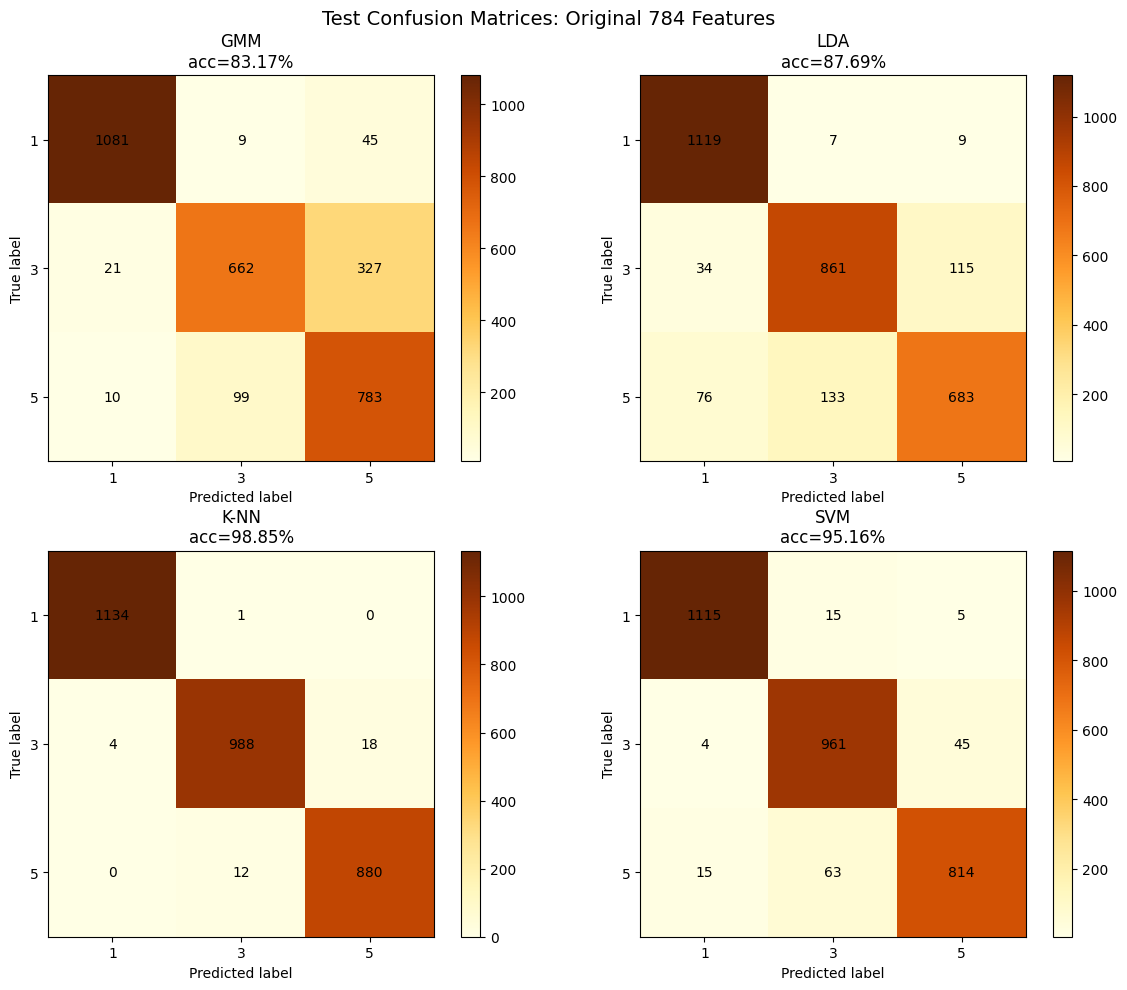

In [11]:
fs="Original 784 Features"

fig,axes=plt.subplots(2,2,figsize=(12,10))

for ax,(name,model) in zip(axes.ravel(),original_models.items()):
    y_pred=model.predict(X_test)
    matrix=confusion_matrix_custom(y_test,y_pred,CLASSES)
    ax.imshow(matrix,cmap="YlOrBr")
    ax.set_title(f"{name}\nacc={accuracy_score(y_test,y_pred):.2f}%")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(len(CLASSES)))
    ax.set_yticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES)
    ax.set_yticklabels(CLASSES)

    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j,i,str(matrix[i,j]),ha="center",va="center")

    fig.colorbar(ax.images[0],ax=ax)

fig.suptitle(f"Test Confusion Matrices: {fs}",fontsize=14)
plt.tight_layout()
plt.show()

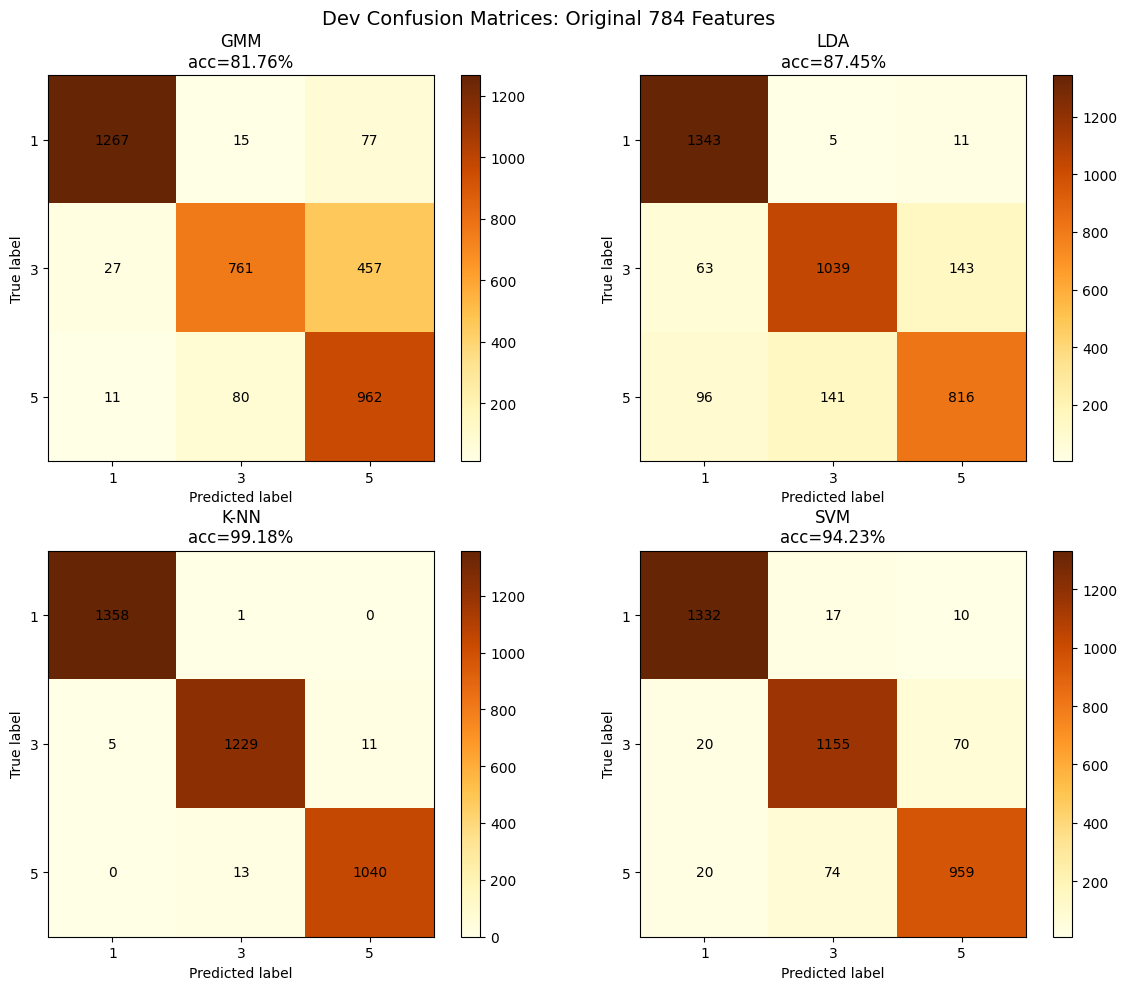

In [12]:
fs="Original 784 Features"

fig,axes=plt.subplots(2,2,figsize=(12,10))

for ax,(name,model) in zip(axes.ravel(),original_models.items()):
    y_pred=model.predict(X_dev)
    matrix=confusion_matrix_custom(y_dev,y_pred,CLASSES)
    ax.imshow(matrix,cmap="YlOrBr")
    ax.set_title(f"{name}\nacc={accuracy_score(y_dev,y_pred):.2f}%")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(len(CLASSES)))
    ax.set_yticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES)
    ax.set_yticklabels(CLASSES)

    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j,i,str(matrix[i,j]),ha="center",va="center")

    fig.colorbar(ax.images[0],ax=ax)

fig.suptitle(f"Dev Confusion Matrices: {fs}",fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
class PCA:
    def __init__(self,n_components):
        self.n_components=n_components

    def fit(self,X):
        self.mean=np.mean(X,axis=0)
        centered=X-self.mean
        covariance=(centered.T@centered)/(len(X)-1)
        values,vectors=np.linalg.eigh(covariance)
        order=np.argsort(values)[::-1]
        self.components=vectors[:,order[:self.n_components]]
        self.explained_variance_ratio=values[order[:self.n_components]]/(np.sum(values)+1e-12)
        return self

    def transform(self,X):
        return (X-self.mean)@self.components

    def fit_transform(self,X):
        self.fit(X)
        return self.transform(X)

In [14]:
PCA_DIMS=[10,20,30,50,100]
pca_results=[]
pca_objects={}
pca_models={}

for k in PCA_DIMS:
    print("\\nPCA components:",k)
    pca=PCA(k)
    Xtr_pca=pca.fit_transform(X_train)
    Xdev_pca=pca.transform(X_dev)
    Xtest_pca=pca.transform(X_test)
    pca_objects[k]=pca
    print("Explained variance:",round(np.sum(pca.explained_variance_ratio),2),"%")
    result,models=run_models(Xtr_pca,y_train,Xdev_pca,y_dev,Xtest_pca,y_test)
    for classifier in result.index:
        pca_results.append({
            "PCA Components":k,
            "Classifier":classifier,
            "Dev Accuracy":result.loc[classifier,"Dev Accuracy"],
            "Test Accuracy":result.loc[classifier,"Test Accuracy"]
        })
    pca_models[k]=models

pca_results_df=pd.DataFrame(pca_results)
pca_results_df

\nPCA components: 10
Explained variance: 0.56 %
Training GMM
GMM Dev: 94.86 % Test: 95.62 %
Training LDA
LDA Dev: 91.19 % Test: 92.56 %
Training K-NN
K-NN Dev: 98.17 % Test: 97.93 %
Training SVM
SVM Dev: 90.89 % Test: 92.33 %
\nPCA components: 20
Explained variance: 0.7 %
Training GMM
GMM Dev: 95.52 % Test: 96.11 %
Training LDA
LDA Dev: 93.03 % Test: 94.17 %
Training K-NN
K-NN Dev: 98.91 % Test: 98.75 %
Training SVM
SVM Dev: 93.46 % Test: 94.5 %
\nPCA components: 30
Explained variance: 0.77 %
Training GMM
GMM Dev: 96.23 % Test: 96.77 %
Training LDA
LDA Dev: 93.68 % Test: 94.83 %
Training K-NN
K-NN Dev: 99.29 % Test: 98.85 %
Training SVM
SVM Dev: 94.07 % Test: 94.8 %
\nPCA components: 50
Explained variance: 0.85 %
Training GMM
GMM Dev: 95.79 % Test: 96.31 %
Training LDA
LDA Dev: 93.9 % Test: 95.16 %
Training K-NN
K-NN Dev: 99.43 % Test: 99.08 %
Training SVM
SVM Dev: 94.67 % Test: 95.23 %
\nPCA components: 100
Explained variance: 0.93 %
Training GMM
GMM Dev: 95.87 % Test: 96.61 %
Trainin

,PCA Components,Classifier,Dev Accuracy,Test Accuracy
0,10,GMM,94.859174,95.620678
1,10,LDA,91.194969,92.558446
2,10,K-NN,98.167897,97.925584
3,10,SVM,90.894176,92.327955
4,20,GMM,95.515450,96.114587
5,20,LDA,93.027071,94.171880
6,20,K-NN,98.906207,98.748765
7,20,SVM,93.464588,94.501152
8,30,GMM,96.226415,96.773131
9,30,LDA,93.683347,94.830425


In [15]:
print("Original 784 features")
display(original_results)

print("PCA feature results")
display(pca_results_df.pivot(index="PCA Components",columns="Classifier",values="Test Accuracy"))

Original 784 features


,Dev Accuracy,Test Accuracy
GMM,81.761006,83.174185
LDA,87.448728,87.685216
K-NN,99.179655,98.847547
SVM,94.230243,95.159697


PCA feature results


Classifier,GMM,K-NN,LDA,SVM
PCA Components,,,,
10,95.620678,97.925584,92.558446,92.327955
20,96.114587,98.748765,94.171880,94.501152
30,96.773131,98.847547,94.830425,94.797498
50,96.312150,99.078038,95.159697,95.225552
100,96.608495,98.913401,95.159697,95.390188


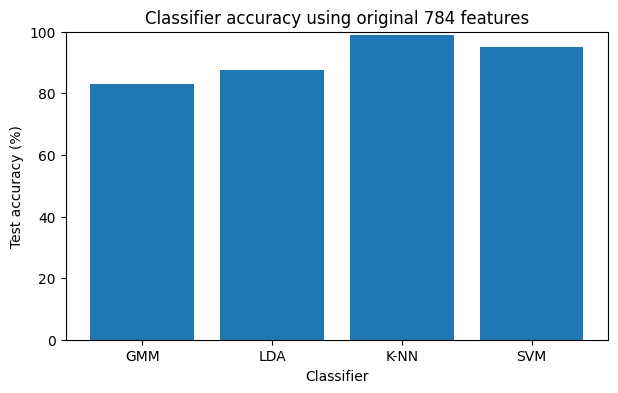

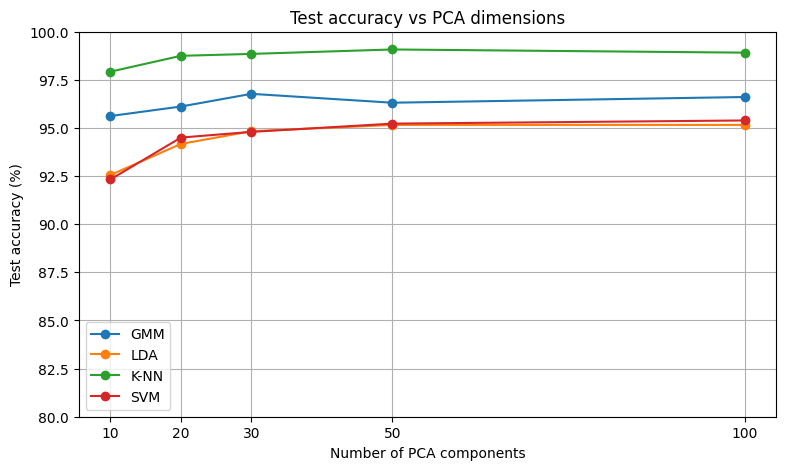

In [16]:
plt.figure(figsize=(7,4))
plt.bar(original_results.index,original_results["Test Accuracy"])
plt.ylabel("Test accuracy (%)")
plt.xlabel("Classifier")
plt.title("Classifier accuracy using original 784 features")
plt.ylim(0,100)
plt.show()

plt.figure(figsize=(9,5))
for classifier in ["GMM","LDA","K-NN","SVM"]:
    values=pca_results_df[pca_results_df["Classifier"]==classifier]
    plt.plot(values["PCA Components"],values["Test Accuracy"],marker="o",label=classifier)
plt.xlabel("Number of PCA components")
plt.ylabel("Test accuracy (%)")
plt.title("Test accuracy vs PCA dimensions")
plt.xticks(PCA_DIMS)
plt.ylim(80,100)
plt.grid(True)
plt.legend()
plt.show()

Best PCA setting: K-NN with 50 components


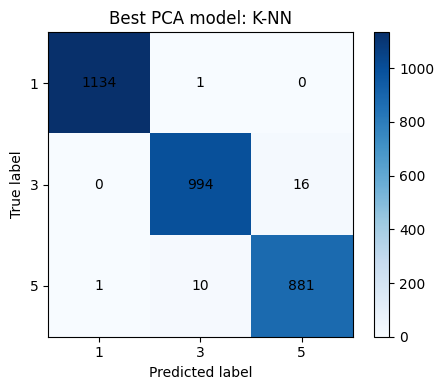

array([[1134,    1,    0],
       [   0,  994,   16],
       [   1,   10,  881]])

In [17]:
best_row=pca_results_df.loc[pca_results_df["Test Accuracy"].idxmax()]
best_k=int(best_row["PCA Components"])
best_name=best_row["Classifier"]
print("Best PCA setting:",best_name,"with",best_k,"components")
best_pca=pca_objects[best_k]
best_model=pca_models[best_k][best_name]
X_test_best=best_pca.transform(X_test)
best_predictions=best_model.predict(X_test_best)
show_confusion_matrix(y_test,best_predictions,"Best PCA model: "+best_name)